In [1]:
from net_4 import CatsDogsModel
import torch.optim as optim
import torch.nn as nn
import os
import torch
import matplotlib.pyplot as plt
from data_processor_3 import process_image

In [2]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * y.size(0)
            correct    += (out.argmax(dim=1) == y).sum().item()
            total      += y.size(0)

    return total_loss / total, correct / total

In [3]:
epochs = 20
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = CatsDogsModel().to(device)
lr = 1e-4
optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()
import yaml
with open("config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.load(f, Loader=yaml.FullLoader)
root = cfg["dataset_root"]
train_loader, val_loader = process_image(root)

[split] train: 20000, val: 5000, val_ratio=0.2, seed=42


## 查看预测错的照片

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC']
plt.rcParams['axes.unicode_minus'] = False


def _to_image(tensor):
    """[3,H,W] -> [H,W,3]，反归一化到 [0,1]"""
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    if tensor.dim() == 4:
        tensor = tensor[0]
    img = tensor.detach().cpu().permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)


@torch.no_grad()
def collect_wrong(model, loader, device):
    model.eval()

    dataset = loader.dataset
    base = dataset.dataset if hasattr(dataset, "dataset") else dataset
    idx_to_class = {v: k for k, v in base.class_to_idx.items()}

    wrong, total, correct = [], 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        prob = torch.softmax(out, dim=1)
        pred = out.argmax(dim=1)

        for i in range(x.size(0)):
            total += 1
            if pred[i].item() == y[i].item():
                correct += 1
            else:
                wrong.append((
                    x[i].cpu(),
                    idx_to_class[y[i].item()],
                    idx_to_class[pred[i].item()],
                    prob[i, pred[i]].item(),
                ))
    return wrong, total, correct


def show_misclassified(model, loader, device, max_show=16, ncols=4):
    wrong, total, correct = collect_wrong(model, loader, device)
    acc = correct / total if total else 0.0
    print(f"总数 {total} | 正确 {correct} | 错误 {len(wrong)} | acc {acc:.4f}")

    if not wrong:
        print("没有预测错误的样本！")
        return

    show = wrong[:max_show]
    nrows = (len(show) + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(3.2 * ncols, 3.2 * nrows))
    axes = np.array(axes).reshape(nrows, ncols)

    for i in range(nrows * ncols):
        r, c = i // ncols, i % ncols
        ax = axes[r, c]
        if i < len(show):
            img_t, true_name, pred_name, p = show[i]
            ax.imshow(_to_image(img_t))
            ax.set_title(f"真: {true_name}\n预: {pred_name} ({p:.2f})",
                         fontsize=10, color="red")
        ax.axis("off")

    plt.suptitle(f"预测错误样本（{len(show)} / {len(wrong)}）", fontsize=14)
    plt.tight_layout()
    plt.show()

In [5]:
loss_train, acc_train = [], []
loss_val,   acc_val   = [], []
best_val_acc = 0.0

os.makedirs('saved_model', exist_ok=True)

for epoch in range(1, epochs+1):
    tr_loss, tr_acc = run_epoch(model, train_loader, loss_fn, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader,   loss_fn)

    loss_train.append(tr_loss); acc_train.append(tr_acc)
    loss_val.append(va_loss);   acc_val.append(va_acc)

    print(f"epoch {epoch:02d} | "
          f"train loss={tr_loss:.4f} acc={tr_acc:.4f} | "
          f"val loss={va_loss:.4f} acc={va_acc:.4f}")

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), 'saved_model/best_model.pth')
        print(f"saved best (val_acc={va_acc:.4f})")

epoch 01 | train loss=0.6065 acc=0.6790 | val loss=0.4940 acc=0.7624
saved best (val_acc=0.7624)
epoch 02 | train loss=0.4200 acc=0.8083 | val loss=0.3974 acc=0.8170
saved best (val_acc=0.8170)
epoch 03 | train loss=0.3140 acc=0.8633 | val loss=0.4191 acc=0.7994
epoch 04 | train loss=0.2687 acc=0.8834 | val loss=0.3746 acc=0.8216
saved best (val_acc=0.8216)
epoch 05 | train loss=0.2369 acc=0.9022 | val loss=0.2679 acc=0.8834
saved best (val_acc=0.8834)
epoch 06 | train loss=0.2100 acc=0.9130 | val loss=0.2372 acc=0.9026
saved best (val_acc=0.9026)
epoch 07 | train loss=0.1948 acc=0.9193 | val loss=0.2363 acc=0.9030
saved best (val_acc=0.9030)
epoch 08 | train loss=0.1804 acc=0.9274 | val loss=0.1981 acc=0.9172
saved best (val_acc=0.9172)
epoch 09 | train loss=0.1703 acc=0.9313 | val loss=0.2373 acc=0.8932
epoch 10 | train loss=0.1634 acc=0.9333 | val loss=0.3362 acc=0.8686
epoch 11 | train loss=0.1509 acc=0.9367 | val loss=0.1830 acc=0.9256
saved best (val_acc=0.9256)
epoch 12 | train 

总数 5000 | 正确 4699 | 错误 301 | acc 0.9398


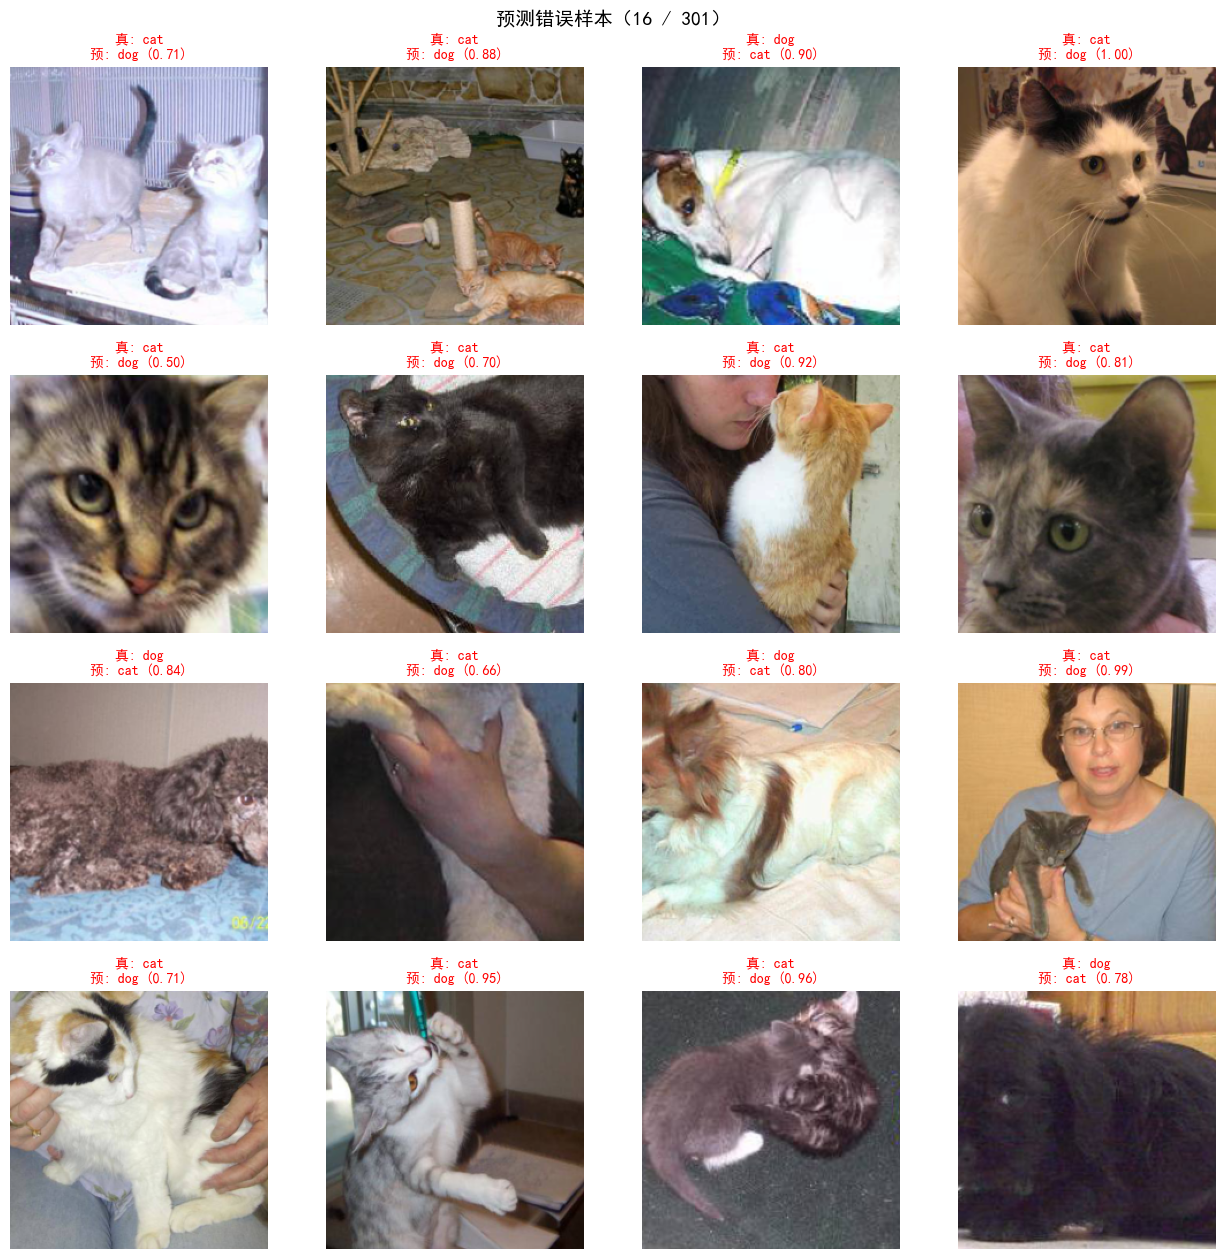

In [6]:
show_misclassified(model, val_loader, device)

图片已保存为 photo_of_result.jpg


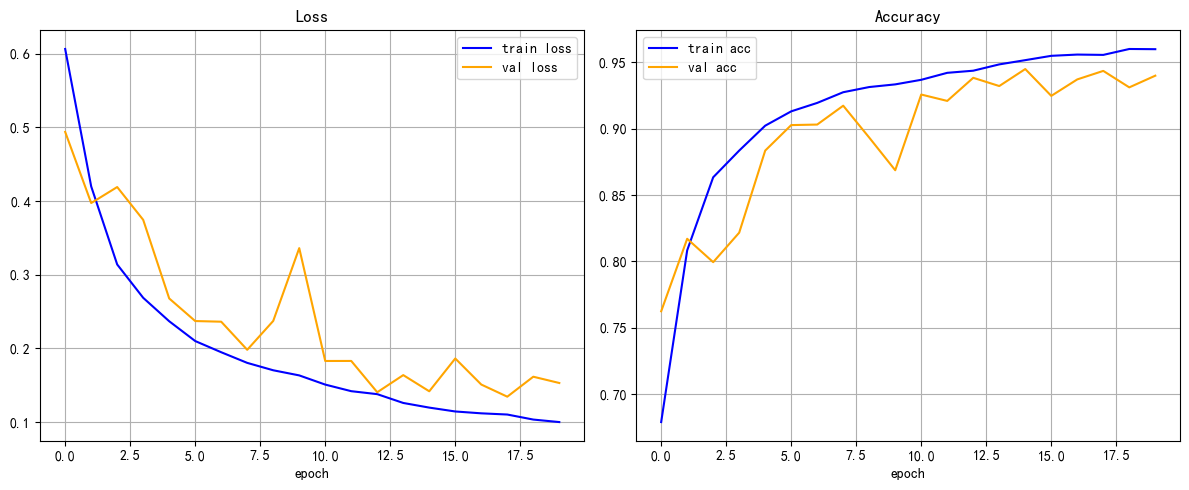

In [7]:
def draw_result(loss_train, loss_val, acc_train, acc_val):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(loss_train, label='train loss', color='blue')
    axes[0].plot(loss_val,   label='val loss',   color='orange')
    axes[0].set_xlabel('epoch')
    axes[0].set_title('Loss')
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(acc_train, label='train acc', color='blue')
    axes[1].plot(acc_val,   label='val acc',   color='orange')
    axes[1].set_xlabel('epoch')
    axes[1].set_title('Accuracy')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()

    # 自动避免覆盖
    base, ext = 'photo_of_result', '.jpg'
    filename = f"{base}{ext}"
    counter = 2
    while os.path.exists(filename):
        filename = f"{base}{counter}{ext}"
        counter += 1
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"图片已保存为 {filename}")
    plt.show()

draw_result(loss_train, loss_val, acc_train, acc_val)